# Neural signal processing and analysis: Zero to hero
**SESSION:** Problem set: Simulating and visualizing data
**TEACHER:** Mike X Cohen, sincxpress.com

Python + MNE version of `uANTS_simulate_problemset.m`.

### INSTRUCTIONS
The goal of this assignment is to simulate time series data
that can be used to test time-series analysis methods.
For each section below:
1. Complete the Python code
2. Put the data into the EEG structure
   - Make sure all relevant fields are accurate (`EEG.data`, `EEG.pnts`, `EEG.trials`, `EEG.srate`, `EEG.nbchan`, `EEG.times`)
3. Plot the data using the function `plot_simEEG()`, and then the MNE way with `plot_mne()`

**NOTE 1:** Obviously, you need to fill in missing code.
**NOTE 2:** Be careful, because sometimes there is incorrect code that doesn't produce coding errors.
Remember: Visualize, and visualize often.

### MATLAB → Python cheat sheet

| MATLAB | Python (numpy) |
|---|---|
| `randn(a,b,c)` | `np.random.randn(a, b, c)` |
| `rand(1,n)` | `np.random.rand(n)` |
| `zeros(a,b,c)` | `np.zeros((a, b, c))` ← note the extra brackets (a tuple) |
| `(0:n-1)` | `np.arange(n)` |
| `linspace(a,b,n)` | `np.linspace(a, b, n)` |
| `.*`  `./`  `.^` | `*`  `/`  `**` (numpy is element-wise by default) |
| `exp`, `sin`, `cos`, `pi` | `np.exp`, `np.sin`, `np.cos`, `np.pi` |
| `1i` | `1j` |
| `ifft`, `real` | `np.fft.ifft`, `np.real` |
| `length(x)` | `len(x)` |
| `for chani=1:N` | `for chani in range(N)` (starts at **0**) |
| `EEG.data(chani,:,triali)` | `EEG.data[chani, :, triali]` |

In [1]:
# ! pip install mne

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace   # works like a MATLAB struct: EEG.srate = 500
import mne

from plot_simEEG import plot_simEEG  # Python version of plot_simEEG.m (in this folder)

mne.set_log_level('error')

### The MNE way
MNE does not use an `EEG` struct. Simulated data go into an `mne.EpochsArray`. Some differences to notice:
- MNE wants the data as **trials × channels × time** (the course uses channels × time × trials), so we `transpose`.
- MNE expects EEG in **volts**. We treat the simulated units as µV and multiply by `1e-6`.
- `epochs.plot_image()` shows every trial as one row of an image, with the ERP below it (`plot_simEEG` draws grey lines instead).
- `epochs.compute_psd()` uses the multitaper method and shows power in dB. `plot_simEEG` uses a plain FFT.
- `epochs.compute_tfr('morlet', ...)` averages **power** (amplitude²) over trials. `plot_simEEG` averages amplitude.
  Its colorbar is in V² (e.g. `1e-11`), because MNE doesn't convert it to µV².

In [61]:
def make_epochs(EEG):
    # put the simulated EEG structure into an MNE Epochs object
    ch_names = ['ch' + str(i) for i in range(EEG.nbchan)]
    info = mne.create_info(ch_names, sfreq=EEG.srate, ch_types='eeg')
    data = EEG.data.transpose(2, 0, 1) * 1e-6   # trials x channels x time, in volts
    return mne.EpochsArray(data, info, tmin=EEG.times[0])


def plot_mne(EEG, chan=0):
    epochs = make_epochs(EEG)
    ch = epochs.ch_names[chan]

    # 1) all trials as an image + ERP
    epochs.plot_image(picks=ch)

    # 2) static power spectrum
    epochs.compute_psd(fmax=40, picks=ch).plot(average=True)

    # 3) time-frequency power with Morlet wavelets (same frequencies/cycles as plot_simEEG)
    freqs = np.linspace(2, 30, 40)
    tfr = epochs.compute_tfr('morlet', freqs=freqs, n_cycles= np.linspace(2, 10, len(freqs)),
                             picks=ch, average=True)
    tfr.plot(picks=ch)

## 1) White noise
The goal of this exercise is to gain basic familiarity with data simulations.
You will create a dataset of white noise and plot it.

> **💡 Hints**
> - `EEG.pnts` = number of time points. For 3 seconds of data at `EEG.srate` Hz, how many samples is that?
> - Pick any reasonable number of `trials` (e.g. tens) and `nbchan` (e.g. 20-ish).
> - `np.random.randn(a, b, c)` makes normally distributed noise. In this course the order is **channels × time × trials**.
> - **Tune:** multiply the noise by a number (noise amplitude), or swap `randn` for `np.random.rand` (uniform noise).
> - **MNE:** `mne.create_info` + `mne.EpochsArray` (see `make_epochs` above).

In [63]:
# create an empty EEG structure
EEG = SimpleNamespace()

# specify EEG parameters
EEG.srate  = 500 # sampling rate in Hz
EEG.pnts   = 1000
EEG.trials = 10
EEG.nbchan = 20

# time vector
EEG.times = np.arange(EEG.pnts) / EEG.srate

# create data as white noise
EEG.data = np.random.randn(EEG.nbchan,EEG.pnts,EEG.trials)

In [64]:
EEG.data.shape, EEG.times.shape

((20, 1000, 10), (1000,))

In [65]:
# EEG.data[0,:,0]

In [66]:
# same trial for all channels
EEG.data[:, :, 0]

array([[ 0.3570059 , -0.69125047,  0.27681476, ...,  1.79260694,
        -0.96310879,  1.82872941],
       [-0.26572391,  0.37468506,  0.75734839, ..., -0.03780695,
         0.18299571, -2.75702016],
       [ 1.38569399,  1.61700136, -1.52559905, ...,  1.30602344,
        -1.58688749, -0.12597819],
       ...,
       [ 0.82611531,  0.16662858,  0.9047859 , ..., -0.26174523,
        -0.34938414,  0.37611868],
       [ 0.18033577, -0.61388869,  0.39879165, ..., -1.01531416,
         1.09321142, -0.56850757],
       [ 1.71602944, -1.3611859 ,  1.60564201, ...,  0.27835773,
         1.5947979 ,  0.43204497]])

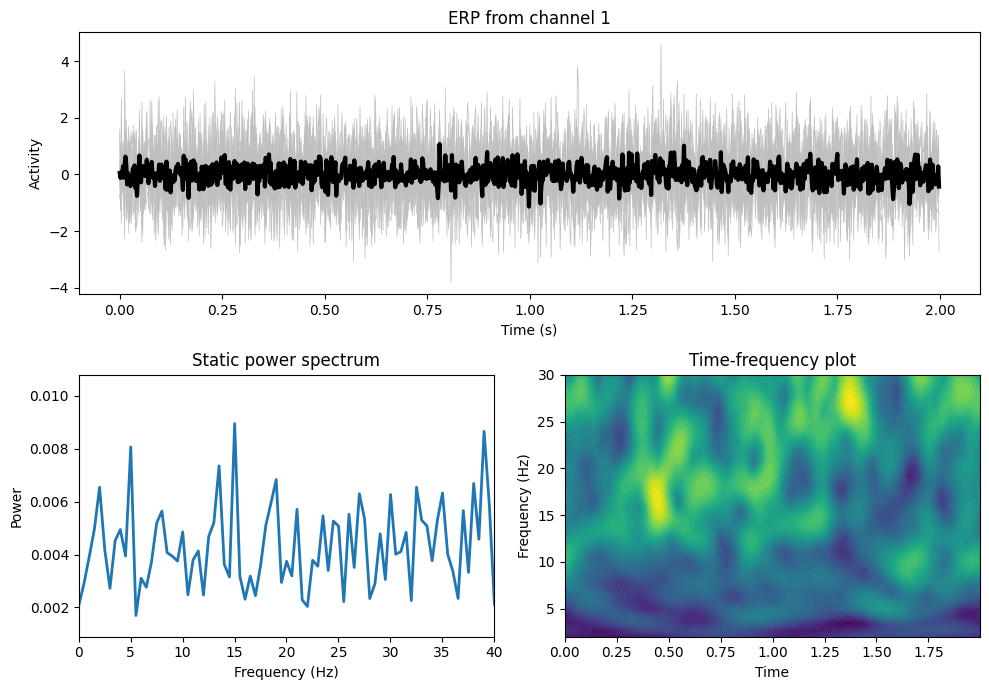

In [67]:
# the function below takes at least one argument (EEG),
# and optionally a second argument (channel number, counted from 0 in Python),
# and optionally a third argument (figure number)
plot_simEEG(EEG,1)   # channel 2 in MATLAB = index 1 in Python

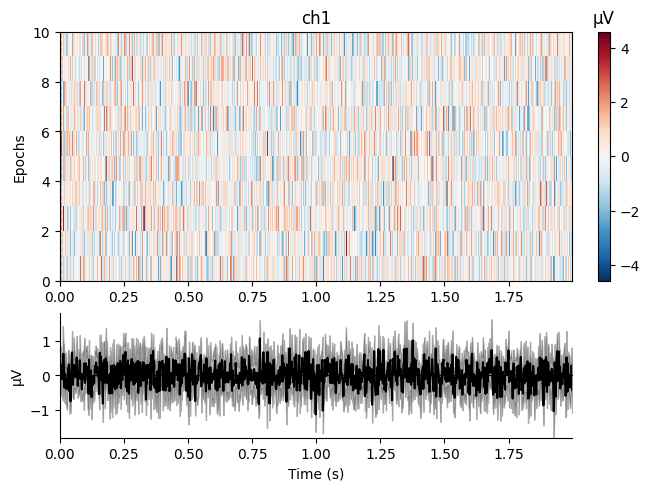

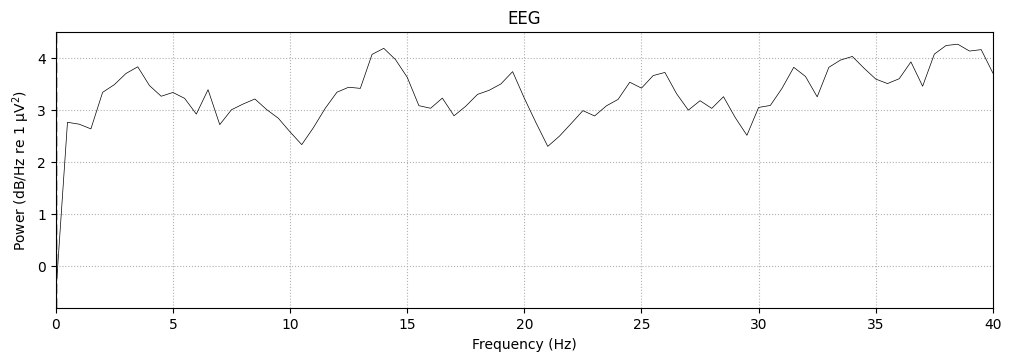

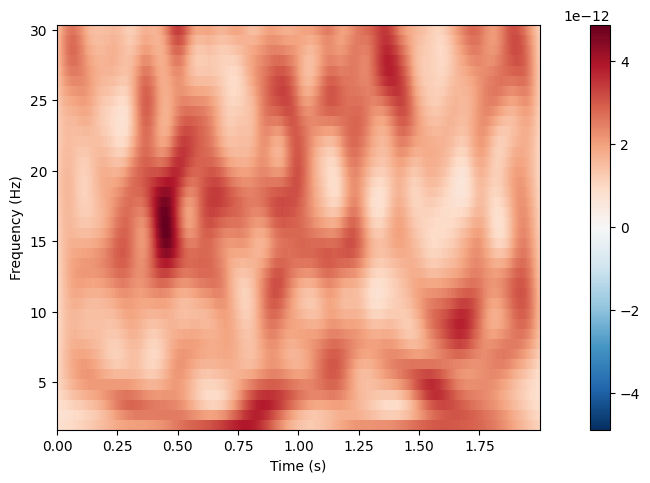

In [68]:
# the same data, the MNE way
plot_mne(EEG, 1)

**Question:** What is the effect of noise amplitude on the resulting graphs?

**Question:** Do the results change if you use normally distributed vs. uniformly distributed noise?

**Question:** Are the results different for different channels? Why or why not?

*Your answers:*

-

## 2) Pink noise
The goal of this exercise is to extend the previous exercise to "pink" noise.
You should create the noise separately on each trial.

> **💡 Hints**
> - `np.zeros((a, b, c))`: the sizes go inside a **tuple** (extra brackets). Use the same shape as in exercise 1.
> - The variable `as` from MATLAB is called `as_` here, because `as` is a reserved word in Python.
> - Don't forget instruction 3: **plot** the result.
> - **Tune:** `ed` (the exponential decay). Small = smoother/slower data, large = closer to white noise.
> - **MNE:** in the PSD from `compute_psd`, white noise is flat and pink noise falls off with frequency.

In [69]:
# feel free to change some parameters compared to above...
EEG.nbchan = 4

# the key parameter of pink noise is the exponential decay (ed)
ed = 50 # try different values!

# initialize EEG data as a zeros matrix
EEG.data = np.zeros((EEG.nbchan,EEG.pnts,EEG.trials))


for chani in range(EEG.nbchan):
    for triali in range(EEG.trials):

        # Note about the code below: This involves creating the signal first in the frequency domain,
        # then transforming it into the time domain. Don't worry if you don't understand the details
        # (you'll learn them tomorrow!); try to plot each step to get a basic idea.

        # generate one-sided 1/f amplitude spectrum
        as_ = np.random.rand(EEG.pnts) * np.exp(-np.arange(EEG.pnts) / ed)

        # Fourier coefficients as amplitudes times random phases
        fc = as_ * np.exp(1j * 2 * np.pi * np.random.rand(len(as_)))

        # inverse Fourier transform to create the noise
        EEG.data[chani, :, triali] = np.real(np.fft.ifft(fc))

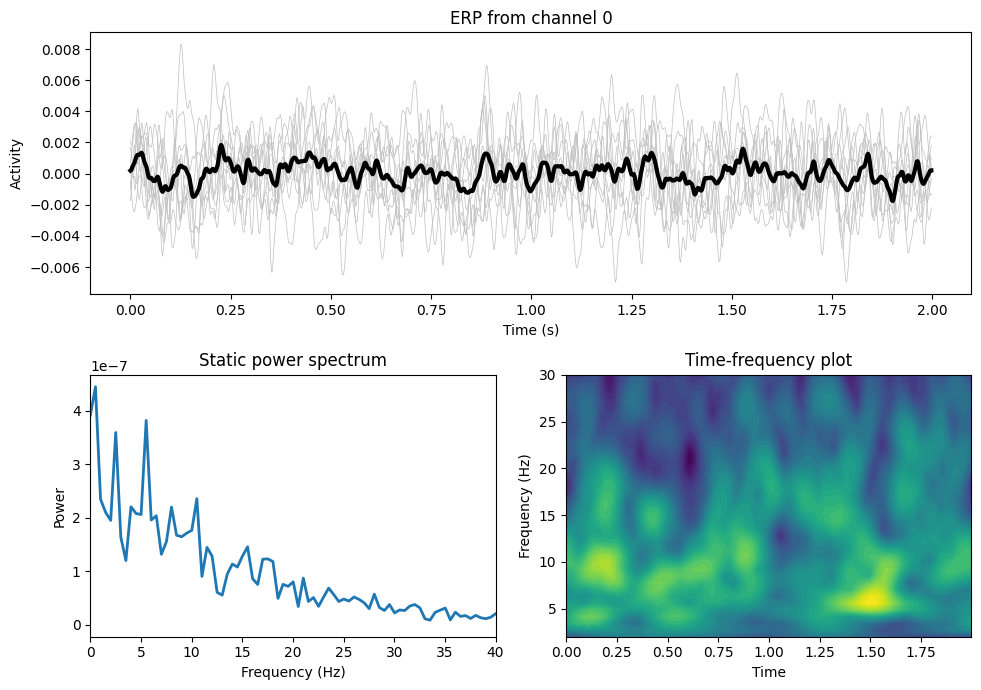

In [71]:
# and plot (your turn: plot_simEEG and plot_mne)
plot_simEEG(EEG)

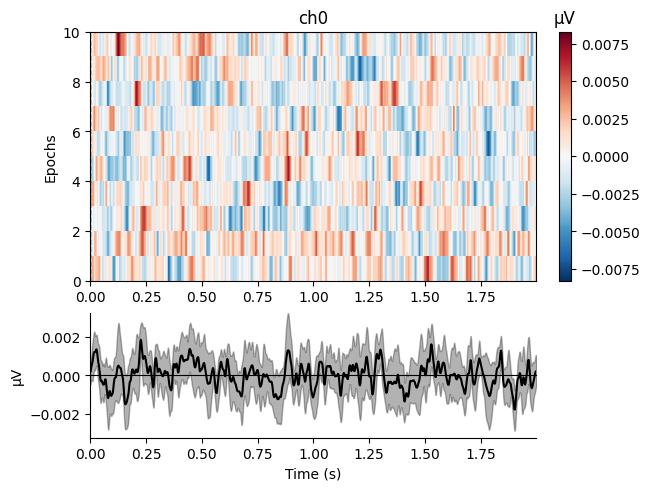

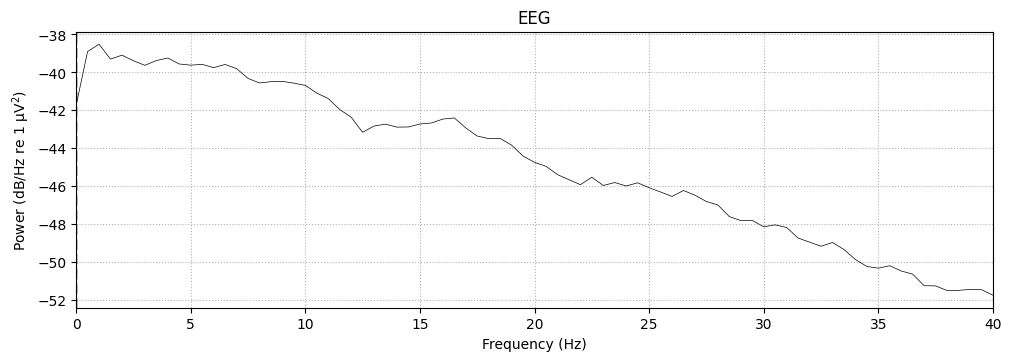

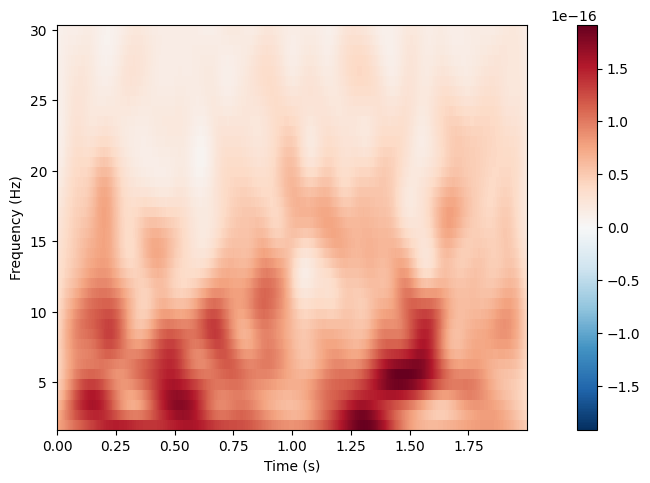

In [72]:
# the MNE way
plot_mne(EEG)

**Question:** Which looks more like real EEG data: white or pink noise? Why do you think this is?

**Question:** Which values of variable `ed` make the data look most like real EEG data?

*Your answers:*

-

## 3) Ongoing stationary
The goal here is to create a dataset with ongoing sinewaves.
There should be multiple sine waves simultaneously in each channel/trial.

> **💡 Hints**
> - A sine wave: `amplitude * np.sin(2*np.pi*frequency*time)`. Use `amps[si]`, `frex[si]` and `EEG.times`.
> - ⚠️ Read the line that stores the data carefully. Does it put the signal into **one channel and one trial**? And the comment says *"plus noise"*...
> - **Tune:** add a random phase per trial, e.g. `np.sin(2*np.pi*f*t + 2*np.pi*np.random.rand())`. The activity is then **non-phase-locked**.
> - **MNE:** compare the ERP in `plot_image` and the TF plot for phase-locked vs. non-phase-locked data.

In [74]:
# list of frequencies and corresponding amplitudes
frex = [ 3, 5, 16 ] # in Hz
amps = [ 3, 4, 5  ] # in arbitrary units


# loop over channels and trials
for chani in range(EEG.nbchan):
    for triali in range(EEG.trials):

        # Note that here the signal is created in the time domain, unlike in the previous example.
        # Some signals are easier to create in the time domain; others in the frequency domain.

        # create a multicomponent sine wave
        sinewave = np.zeros(EEG.pnts)
        for si in range(len(frex)):
            sinewave = sinewave + si

        # data as a sine wave plus noise
        EEG.data = sinewave

IndexError: too many indices for array: array is 1-dimensional, but 3 were indexed

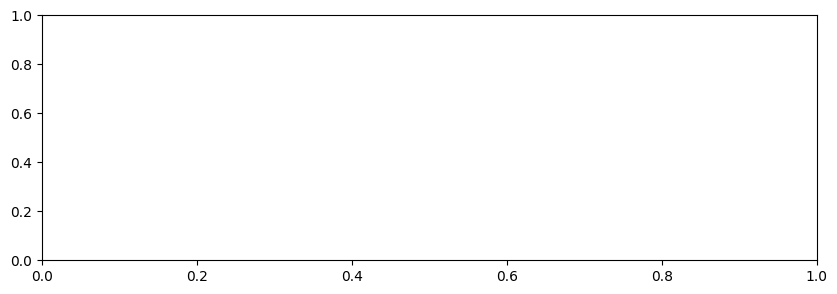

In [75]:
# and plot
plot_simEEG(EEG, 0, 2)   # channel 1 in MATLAB = index 0 in Python

In [ ]:
# the MNE way
plot_mne(EEG, 0)

**Question:** What can you change in the code above to make the EEG activity non-phase-locked over trials?

**Question:** Which of the plots look different for phase-locked vs. non-phase-locked?
(Hint: plot them in different figures to facilitate comparison.) Are you surprised about the differences?

**Question:** Are all frequencies equally well represented in the 'static' and 'dynamic' power spectra?
Can you change the parameters to make the spectral peaks more or less visible in the two plots?

*Your answers:*

-

## 4) Ongoing nonstationary
Here you want to create narrowband non-stationary data.
This is starting to be more "realistic" (in a signal-characteristic sense) for EEG data.

> **💡 Hints**
> - "Taper by the Gaussian" means multiplying the Fourier coefficients `fc` element-wise by the Gaussian `fg`. In MATLAB that's `.*`, in numpy plain `*`.
> - **Tune:** `peakfreq` and `fwhm`. A small FWHM gives a clean, sine-like signal. A large FWHM looks more like noise.
> - **Two frequency ranges:** make a second Gaussian (`fg2` at another `peakfreq`) and taper with `fg + fg2`.
> - **MNE:** the peak in `compute_psd` should sit at `peakfreq`, and its width follows `fwhm`.

In [ ]:
# signal parameters in Hz
peakfreq = 14
fwhm     =  5


# frequencies
hz = np.linspace(0, EEG.srate, EEG.pnts)

# create frequency-domain Gaussian
s  = fwhm * (2*np.pi - 1) / (4*np.pi) # normalized width
x  = hz - peakfreq                     # shifted frequencies
fg = np.exp(-.5 * (x/s)**2)            # gaussian


for chani in range(EEG.nbchan):
    for triali in range(EEG.trials):

        # As with previous simulations, don't worry if you don't understand the mechanisms;
        # that will be clear tomorrow. Instead, you can plot each step to try to build intuition.

        # Fourier coefficients of random spectrum
        fc = np.random.rand(EEG.pnts) * np.exp(1j * 2 * np.pi * np.random.rand(EEG.pnts))

        # taper Fourier coefficients by the Gaussian
        fc =

        # go back to time domain to get EEG data
        EEG.data[chani, :, triali] = np.real(np.fft.ifft(fc))

In [ ]:
# and plot
plot_simEEG(EEG)

In [ ]:
# the MNE way
plot_mne(EEG)

**Question:** What is the effect of FWHM on the results? Is larger or smaller more realistic?

**Question:** Can you modify the code to have narrowband activity at two different frequency ranges?

*Your answers:*

-

## 5) Transients #1: Gaussian
All the exercises above were for ongoing signals. Now we move to transients.
Start with a Gaussian.

> **💡 Hints**
> - A time-domain Gaussian: `np.exp(-(EEG.times - trialpeak)**2 / (2*width**2))`
> - ⚠️ The line that stores the data **doesn't use `gaus`**, and its formula is wrong: it has no peak time and no `2*width**2`. In MATLAB `^` on a vector gives an error, but in numpy `**` just runs, so you get no warning.
> - **Tune (jitter):** `trialpeak = peaktime + np.random.randn() * jitter`. Try jitter = 0, 0.05, 0.25, 0.5...
> - **MNE:** in `plot_image`, jitter shows up as the peaks shifting from row to row, and the ERP below gets flatter.

In [ ]:
# gaussian parameters (in seconds)
peaktime = 1
width = .1

# re-initialize EEG data
EEG.data = np.zeros((EEG.nbchan, EEG.pnts, EEG.trials))

for chani in range(EEG.nbchan):
    for triali in range(EEG.trials):

        # generate time-domain gaussian
        trialpeak = peaktime
        gaus =

        # data are the Gaussian
        EEG.data[chani, :, triali] = np.exp(-EEG.times**2 / width)

In [ ]:
# and plot
plot_simEEG(EEG, 0, 1)

In [ ]:
# the MNE way
plot_mne(EEG, 0)

**Questions:** What happens if you add random jitter to the peaktime on each trial?
How much jitter until the ERP is nearly gone?

*Your answers:*

-

## 6) Transients #2: oscillations w/ Gaussian
Finally, we get to the most useful simulations for time-frequency analysis:
time-limited narrow-band activity. This is done by multiplying a Gaussian with a sine wave.

> **💡 Hints**
> - ⚠️ `np.cos(EEG.times)` is missing the frequency. A cosine at `sfreq` Hz is `np.cos(2*np.pi*sfreq*EEG.times)`.
> - ⚠️ The data line stores only `gaus`. It should be the sine wave **times** the Gaussian (`sw * gaus`).
> - **Tune (non-phase-locked):** give the sine wave a random phase per trial: `np.cos(2*np.pi*sfreq*EEG.times + 2*np.pi*np.random.rand())`.
> - **More EEG-like:** add some noise (pink noise from #2!).
> - **MNE:** compare the ERP in `plot_image` with the TF plot. Non-phase-locked activity disappears from the ERP but **not** from the TF power.

In [ ]:
# sine wave frequency
sfreq = 8

# gaussian parameters (in seconds)
peaktime = 1
width = .2


# re-initialize EEG data
EEG.data = np.zeros((EEG.nbchan, EEG.pnts, EEG.trials))

for chani in range(EEG.nbchan):
    for triali in range(EEG.trials):

        # generate time-domain gaussian
        trialpeak = peaktime + np.random.randn() / 5
        gaus = np.exp(-(EEG.times - trialpeak)**2 / (2 * width**2))


        # generate sine wave with same phase
        sw = np.cos(EEG.times)


        # data are sine wave times Gaussian
        EEG.data[chani, :, triali] = gaus

In [ ]:
# and plot
plot_simEEG(EEG, 0, 1)

In [ ]:
# the MNE way
plot_mne(EEG, 0)

**Question:** Do the results look realistic? What can you change to make it look even more EEG-like?

**Question:** How can you modify the code to make the transient non-phase-locked?
Which of the three data plots are most affected by phase-locked vs. non-phase-locked?

*Your answers:*

-

## More exercises for more fun!

## 7) Add pink noise to #5

> **💡 Hints**
> - Inside the trial loop: make the Gaussian (#5), make pink noise (#2), and add them together.
> - ⚠️ The pink noise from #2 is **tiny** (about 0.01) compared to the Gaussian (1). Scale it first, e.g. `noise = noise / np.std(noise)`, then multiply by a noise amplitude.
> - **Tune:** the noise amplitude and `ed`. How noisy can it get before the ERP is hard to see? Do the MNE plots handle it better than the single-trial lines?

In [ ]:
# your code here

In [ ]:
# and plot

## 8) Combine #4 and #6 to make a transient (Gaussian-windowed) non-stationary signal

> **💡 Hints**
> - In #6, replace the pure cosine `sw` with the narrowband non-stationary signal from #4 (random spectrum × frequency Gaussian `fg` → `np.real(np.fft.ifft(...))`).
> - Then multiply it by the time-domain Gaussian `gaus` from #6.
> - Scale the narrowband signal (e.g. divide by its `np.std`) so the amplitude is around 1.
> - **Tune:** `peakfreq`, `fwhm` (frequency), `peaktime`, `width` (time). In the TF plot the "blob" should sit at `peaktime` × `peakfreq`.

In [ ]:
# your code here

In [ ]:
# and plot

Done.